# ISIC 2019 Binary Classification: ResNet-200D

This notebook implements a **Multi-Modal ResNet-200D** for binary classification (Benign vs Malignant) of skin lesions. It is designed to act as a robust base model for our high-performance ensemble.

## Key Features:
- **Architecture**: `resnet200d` backbone from `timm`.
- **Multi-Modal**: Integrates 11 clinical metadata features (age, sex, anatomical site) alongside image features.
- **Augmentations**: Heavy spatial augmentations, CLAHE, and CoarseDropout (DropBlock).
- **Training Strategy**: Gradual unfreezing (3 warmup epochs) followed by full fine-tuning with Cosine Annealing LR and Focal Loss.
- **Inference**: 3-View Test-Time Augmentation (TTA) and `.npy` export for OOF stacking.

In [1]:
import os
import gc
import time
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, confusion_matrix, roc_curve

import timm

warnings.filterwarnings('ignore')

In [2]:
# ── CODE CELL 2: Configuration ──────────────────────────────────────────
class CFG:
    seed = 42
    model_name = 'resnet200d'
    img_size = 224
    batch_size = 32
    num_workers = 4
    warmup_epochs = 3
    num_epochs = 30
    lr = 5e-5
    weight_decay = 1e-3
    patience = 5
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.seed)

DATA_DIR = '/kaggle/input/notebooks/nandini143/data-preparation'
OUTPUT_DIR = '/kaggle/working/'
SAVE_PATH = os.path.join(OUTPUT_DIR, 'resnet200d_best.pth')

In [3]:
# ── CODE CELL 3: Data Loading & Dataset (UPDATED) ─────────────────────────
train_df = pd.read_csv(os.path.join(DATA_DIR, 'binary_train.csv'))
val_df   = pd.read_csv(os.path.join(DATA_DIR, 'binary_val.csv'))
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'binary_test.csv'))

# Override old paths to point to your new Kaggle dataset directory
NEW_IMG_DIR = '/kaggle/input/notebooks/nandini143/data-preparation/preprocessed'
train_df['image_path'] = train_df['image'].apply(lambda x: os.path.join(NEW_IMG_DIR, f"{x}.jpg"))
val_df['image_path']   = val_df['image'].apply(lambda x: os.path.join(NEW_IMG_DIR, f"{x}.jpg"))
test_df['image_path']  = test_df['image'].apply(lambda x: os.path.join(NEW_IMG_DIR, f"{x}.jpg"))

META_COLS = ['age_norm', 'sex_encoded'] + [c for c in train_df.columns if c.startswith('site_')]
print(f"Metadata Features ({len(META_COLS)}): {META_COLS}")

class ISICDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.image_paths = df['image_path'].values
        self.labels = df['binary_label'].values  # Fixed column name
        self.meta = df[META_COLS].values.astype(np.float32)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        
        image = cv2.imread(img_path)
        if image is None:
            image = np.zeros((CFG.img_size, CFG.img_size, 3), dtype=np.uint8)
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
        if self.transform:
            res = self.transform(image=image)
            image = res['image']
            
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        meta = torch.tensor(self.meta[idx], dtype=torch.float32)
        return image, meta, label

Metadata Features (11): ['age_norm', 'sex_encoded', 'site_oral_genital', 'site_posterior_torso', 'site_unknown', 'site_head_neck', 'site_lower_extremity', 'site_lateral_torso', 'site_palms_soles', 'site_upper_extremity', 'site_anterior_torso']


In [4]:
# ── CODE CELL 4: Augmentations ────────────────────────────────────────
train_transform = A.Compose([
    A.Resize(CFG.img_size, CFG.img_size),
    A.Transpose(p=0.5),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
    A.OneOf([
        A.CLAHE(clip_limit=2.0),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2),
    ], p=0.5),
    A.HueSaturationValue(p=0.3),
    A.CoarseDropout(max_holes=8, max_height=int(CFG.img_size*0.1), max_width=int(CFG.img_size*0.1), p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(CFG.img_size, CFG.img_size),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

train_dataset = ISICDataset(train_df, transform=train_transform)
val_dataset   = ISICDataset(val_df, transform=val_transform)
test_dataset  = ISICDataset(test_df, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=CFG.batch_size, shuffle=True, num_workers=CFG.num_workers, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=CFG.batch_size, shuffle=False, num_workers=CFG.num_workers, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=CFG.batch_size, shuffle=False, num_workers=CFG.num_workers, pin_memory=True)

In [5]:
# ── CODE CELL 5: Multi-Modal Model Definition ─────────────────────────
class MultiModalModel(nn.Module):
    def __init__(self, model_name=CFG.model_name, num_classes=1, num_meta_features=len(META_COLS), pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        in_features = self.backbone.num_features
        
        self.meta_branch = nn.Sequential(
            nn.Linear(num_meta_features, 64),
            nn.BatchNorm1d(64),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.SiLU()
        )
        
        self.head = nn.Sequential(
            nn.Linear(in_features + 32, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )
        
    def forward(self, image, meta):
        img_features = self.backbone(image)
        meta_features = self.meta_branch(meta)
        combined = torch.cat([img_features, meta_features], dim=1)
        output = self.head(combined)
        return output.squeeze(-1)

model = MultiModalModel().to(CFG.device)

model.safetensors:   0%|          | 0.00/260M [00:00<?, ?B/s]

In [6]:
# ── CODE CELL 6: Focal Loss (UPDATED) ─────────────────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.bce_with_logits = nn.BCEWithLogitsLoss(reduction='none')
        
    def forward(self, inputs, targets):
        bce_loss = self.bce_with_logits(inputs, targets)
        pt = torch.exp(-bce_loss)
        
        # Calculate dynamic alpha factor based on target class
        alpha_factor = targets * self.alpha + (1 - targets) * (1 - self.alpha)
        
        focal_loss = alpha_factor * (1 - pt)**self.gamma * bce_loss
        return focal_loss.mean()

criterion = FocalLoss()
scaler = torch.amp.GradScaler('cuda')

In [7]:
# ── CODE CELL 7: Training Helpers (UPDATED) ───────────────────────────────
def train_one_epoch(model, dataloader, optimizer, criterion, scaler, device):
    model.train()
    running_loss = 0.0
    all_labels, all_probs = [], []
    
    for images, meta, labels in tqdm(dataloader, leave=False, desc='Train'):
        images, meta, labels = images.to(device), meta.to(device), labels.to(device)
        optimizer.zero_grad()
        
        with torch.amp.autocast('cuda'):
            logits = model(images, meta)
            loss = criterion(logits, labels)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * images.size(0)
        
        # Added .float() here
        probs = torch.sigmoid(logits).detach().float().cpu().numpy()
        all_probs.extend(probs)
        all_labels.extend(labels.cpu().numpy())
        
    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_auc = roc_auc_score(all_labels, all_probs)
    epoch_acc = accuracy_score(all_labels, (np.array(all_probs) > 0.5).astype(int))
    return epoch_loss, epoch_auc, epoch_acc

def validate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_labels, all_probs = [], []
    
    with torch.no_grad():
        for images, meta, labels in tqdm(dataloader, leave=False, desc='Val'):
            images, meta, labels = images.to(device), meta.to(device), labels.to(device)
            with torch.amp.autocast('cuda'):
                logits = model(images, meta)
                loss = criterion(logits, labels)
                
            running_loss += loss.item() * images.size(0)
            
            # Added .float() here
            probs = torch.sigmoid(logits).float().cpu().numpy()
            all_probs.extend(probs)
            all_labels.extend(labels.cpu().numpy())
            
    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_auc = roc_auc_score(all_labels, all_probs)
    epoch_acc = accuracy_score(all_labels, (np.array(all_probs) > 0.5).astype(int))
    return epoch_loss, epoch_auc, epoch_acc, all_labels, all_probs

def freeze_backbone(model):
    for param in model.backbone.parameters():
        param.requires_grad = False
    for param in model.meta_branch.parameters():
        param.requires_grad = True
    for param in model.head.parameters():
        param.requires_grad = True

# FIXED: Un-indented this function so it is available globally
def unfreeze_all(model):
    for param in model.parameters():
        param.requires_grad = True

In [8]:
# ── CODE CELL 8: Main Training Loop ───────────────────────────────────
history = {'train_loss': [], 'val_loss': [], 'train_auc':  [], 'val_auc': []}
best_val_auc, patience_counter = 0.0, 0
start_time = time.time()

print(f"\n🚀 Starting ResNet-200D Training (Gradual Unfreezing)")
print(f"   Phase 1 — Warmup  : Epochs 1–{CFG.warmup_epochs} (head only, backbone frozen)")
print(f"   Phase 2 — Full FT : Epochs {CFG.warmup_epochs+1}–{CFG.num_epochs} (all layers)")
print("=" * 60)

# Phase 1: Warmup
freeze_backbone(model)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=CFG.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.warmup_epochs, eta_min=1e-5)

for epoch in range(1, CFG.num_epochs + 1):
    epoch_start = time.time()
    
    if epoch == CFG.warmup_epochs + 1:
        unfreeze_all(model)
        optimizer = optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.num_epochs - CFG.warmup_epochs, eta_min=1e-6)
        print(f"\n  🔓 Epoch {epoch}: Backbone UNFROZEN — Full fine-tuning begins!\n")
        
    train_loss, train_auc, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, scaler, CFG.device)
    val_loss, val_auc, val_acc, _, _ = validate(model, val_loader, criterion, CFG.device)
    
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)
    
    elapsed = time.time() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']
    
    print(f"Epoch [{epoch:>2}/{CFG.num_epochs}] | "
          f"Train Loss: {train_loss:.4f} AUC: {train_auc:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} AUC: {val_auc:.4f} Acc: {val_acc:.4f} | "
          f"LR: {current_lr:.2e} | ⏱ {elapsed:.0f}s")
          
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_auc': val_auc,
            'val_loss': val_loss,
        }, SAVE_PATH)
        print(f"   ✅ New best model saved! Val AUC: {val_auc:.4f}")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= CFG.patience:
            print(f"\n⏹️  Early stopping at epoch {epoch}. Best Val AUC: {best_val_auc:.4f}")
            break

print(f"\n✅ Training Complete! Time: {(time.time()-start_time)/60:.1f} mins")


🚀 Starting ResNet-200D Training (Gradual Unfreezing)
   Phase 1 — Warmup  : Epochs 1–3 (head only, backbone frozen)
   Phase 2 — Full FT : Epochs 4–30 (all layers)


Train:   0%|          | 0/633 [00:00<?, ?it/s]

Val:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [ 1/30] | Train Loss: 0.0533 AUC: 0.8239 Acc: 0.7330 | Val Loss: 0.0439 AUC: 0.8873 Acc: 0.7276 | LR: 7.53e-04 | ⏱ 131s
   ✅ New best model saved! Val AUC: 0.8873


Train:   0%|          | 0/633 [00:00<?, ?it/s]

...

Val:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [19/30] | Train Loss: 0.0143 AUC: 0.9884 Acc: 0.9407 | Val Loss: 0.0335 AUC: 0.9563 Acc: 0.8985 | LR: 1.85e-05 | ⏱ 373s


Train:   0%|          | 0/633 [00:00<?, ?it/s]

Val:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch [20/30] | Train Loss: 0.0138 AUC: 0.9894 Acc: 0.9398 | Val Loss: 0.0342 AUC: 0.9570 Acc: 0.9025 | LR: 1.58e-05 | ⏱ 332s

⏹️  Early stopping at epoch 20. Best Val AUC: 0.9592

✅ Training Complete! Time: 106.6 mins


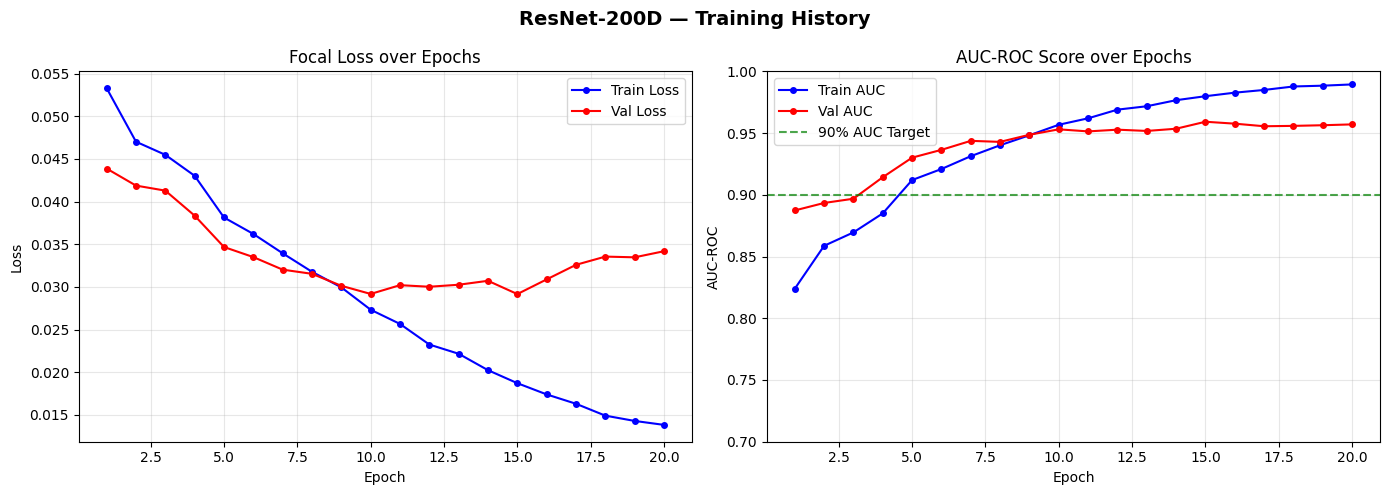

In [9]:
# ── CODE CELL 9: Plot Training Curves ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ResNet-200D — Training History', fontsize=14, fontweight='bold')
epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(epochs_ran, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Focal Loss over Epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['train_auc'], 'b-o', label='Train AUC', markersize=4)
axes[1].plot(epochs_ran, history['val_auc'],   'r-o', label='Val AUC',   markersize=4)
axes[1].axhline(y=0.90, color='green', linestyle='--', alpha=0.7, label='90% AUC Target')
axes[1].set_title('AUC-ROC Score over Epochs')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC-ROC')
axes[1].legend(); axes[1].grid(alpha=0.3); axes[1].set_ylim([0.7, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'resnet200d_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

✅ Best checkpoint loaded (epoch 15, Val AUC: 0.9592)


  TTA Inference:   0%|          | 0/80 [00:00<?, ?it/s]


  RESNET-200D — TEST SET RESULTS (3-View TTA)

  AUC-ROC  : 0.9623
  Accuracy : 0.8958

  Classification Report:
               precision    recall  f1-score   support

   Benign (0)     0.8787    0.9688    0.9215      1600
Malignant (1)     0.9351    0.7709    0.8451       934

     accuracy                         0.8958      2534
    macro avg     0.9069    0.8698    0.8833      2534
 weighted avg     0.8995    0.8958    0.8933      2534



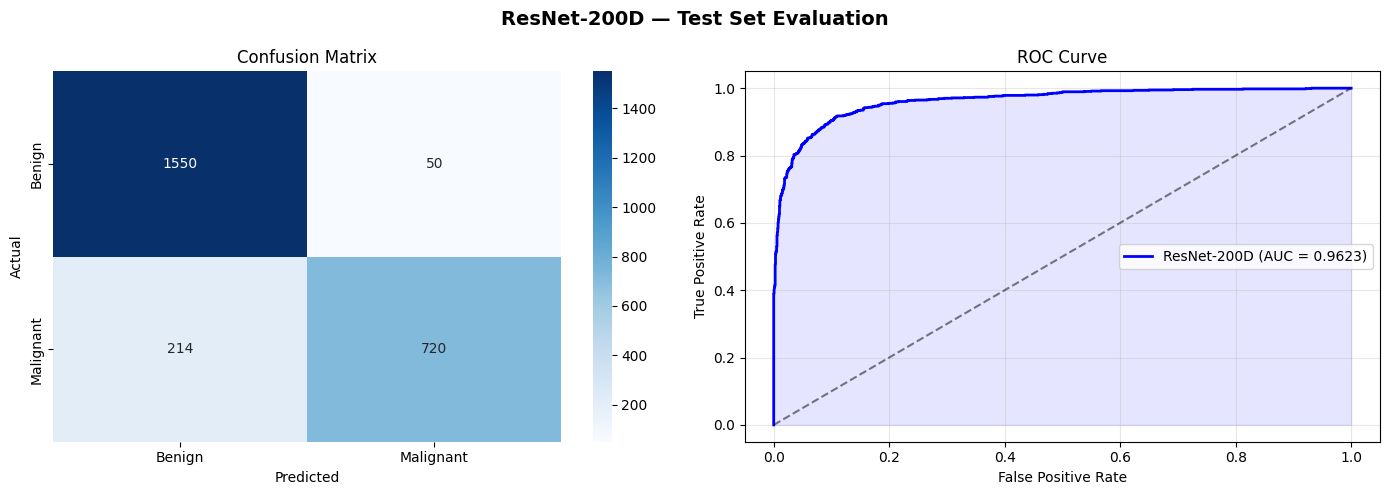

In [10]:
# ── CODE CELL 10: TTA Evaluation & Plot ROC ───────────────────────────
checkpoint = torch.load(SAVE_PATH, map_location=CFG.device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"✅ Best checkpoint loaded (epoch {checkpoint['epoch']}, Val AUC: {checkpoint['val_auc']:.4f})")

def predict_with_tta(model, loader, device):
    model.eval()
    all_labels, all_probs_0, all_probs_h, all_probs_v = [], [], [], []
    
    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  TTA Inference", leave=False):
            images, meta, labels = images.to(device, non_blocking=True), meta.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            with torch.amp.autocast('cuda'):
                logits_orig  = model(images, meta)
                logits_hflip = model(torch.flip(images, dims=[3]), meta)
                logits_vflip = model(torch.flip(images, dims=[2]), meta)
                
            all_probs_0.extend(torch.sigmoid(logits_orig).float().cpu().numpy())
            all_probs_h.extend(torch.sigmoid(logits_hflip).float().cpu().numpy())
            all_probs_v.extend(torch.sigmoid(logits_vflip).float().cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    tta_probs = (np.array(all_probs_0) + np.array(all_probs_h) + np.array(all_probs_v)) / 3.0
    tta_labels = np.array(all_labels)
    tta_preds = (tta_probs >= 0.5).astype(int)
    tta_auc = roc_auc_score(tta_labels, tta_probs)
    tta_acc = accuracy_score(tta_labels, tta_preds)
    return tta_auc, tta_acc, tta_labels, tta_probs, tta_preds

test_auc, test_acc, test_labels, test_probs, test_preds = predict_with_tta(model, test_loader, CFG.device)

print("\n" + "=" * 60)
print("  RESNET-200D — TEST SET RESULTS (3-View TTA)")
print("=" * 60)
print(f"\n  AUC-ROC  : {test_auc:.4f}")
print(f"  Accuracy : {test_acc:.4f}")
print("\n  Classification Report:")
print(classification_report(test_labels, test_preds, target_names=['Benign (0)', 'Malignant (1)'], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ResNet-200D — Test Set Evaluation', fontsize=14, fontweight='bold')
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[0].set_title('Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(test_labels, test_probs)
axes[1].plot(fpr, tpr, 'b-', linewidth=2, label=f'ResNet-200D (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].fill_between(fpr, tpr, alpha=0.1, color='blue')
axes[1].set_title('ROC Curve'); axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'resnet200d_evaluation.png'), dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# ── CODE CELL 11: Save OOF Arrays for Ensemble ─────────────────────────
model.eval()
val_probs_tta = [[], [], []]   
val_labels_all = []

with torch.no_grad():
    for images, meta, labels in tqdm(val_loader, desc='  Val TTA', leave=False):
        images, meta, labels = images.to(CFG.device, non_blocking=True), meta.to(CFG.device, non_blocking=True), labels.to(CFG.device, non_blocking=True)
        
        with torch.amp.autocast('cuda'):
            val_probs_tta[0].extend(torch.sigmoid(model(images, meta)).float().cpu().numpy())
            val_probs_tta[1].extend(torch.sigmoid(model(torch.flip(images, dims=[3]), meta)).float().cpu().numpy())
            val_probs_tta[2].extend(torch.sigmoid(model(torch.flip(images, dims=[2]), meta)).float().cpu().numpy())
            val_labels_all.extend(labels.cpu().numpy())

val_probs  = (np.array(val_probs_tta[0]) + np.array(val_probs_tta[1]) + np.array(val_probs_tta[2])) / 3.0
val_labels = np.array(val_labels_all)

np.save(os.path.join(OUTPUT_DIR, 'resnet200d_val_probs.npy'), val_probs)
np.save(os.path.join(OUTPUT_DIR, 'resnet200d_val_labels.npy'), val_labels)
np.save(os.path.join(OUTPUT_DIR, 'resnet200d_test_probs.npy'), test_probs)
np.save(os.path.join(OUTPUT_DIR, 'resnet200d_test_labels.npy'), test_labels)

print('✅ All outputs saved for Stacking Ensemble:')
print(f'   resnet200d_test_probs.npy   — {len(test_probs)} predictions')
print(f'   resnet200d_val_probs.npy    — {len(val_probs)} predictions (for meta-learner)')


  Val TTA:   0%|          | 0/80 [00:00<?, ?it/s]

✅ All outputs saved for Stacking Ensemble:
   resnet200d_test_probs.npy   — 2534 predictions
   resnet200d_val_probs.npy    — 2533 predictions (for meta-learner)
